## Análisis descriptivo de las noticias

Análisis descriptivo de las noticias para identificación de emojis, caracteres extraños, palabras extrañas, ortografía y pérdida de contexto ante limpiezas habituales.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(raiz))

from src.analisis_texto import (
    Analizador_Detonantes, Analizador_Emojis, Analizador_Impacto_Limpieza,
    Analizador_Palabras_Raras, AnalizadorOrtografia, Carga_Corpus,
    Inventario_Caracteres, Perfilador_Textos, palabra_en_contexto,
)

ruta_datos = raiz / "data" / "interim" / "noticias_unidas_local.csv"
idiomas = ["en", "es"]
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [2]:
def titulo(texto):
    display(Markdown(f"## {texto}"))


def seccion_caracteres(df):
    titulo("1. Inventario de caracteres y caracteres raros")
    inventario = Inventario_Caracteres(df["texto"])
    display(inventario.resumen_por_tipo())
    for tipo in ["simbolo_raro", "control_o_invisible", "espacio_raro", "letra_otro_alfabeto"]:
        tabla = inventario.por_tipo(tipo, top=15)
        if not tabla.empty:
            display(Markdown(f"**{tipo}** (top 15)"))
            display(tabla.reset_index(drop=True))
    return inventario


def seccion_perfil(df, inventario):
    titulo("2. Perfil por documento (por label y por fuente)")
    perfil = Perfilador_Textos(inventario.caracteres_raros()).perfilar(df)
    display(Markdown("**Por label**"))
    display(Perfilador_Textos.prevalencia(perfil, "label"))
    display(Markdown("**Por fuente**"))
    display(Perfilador_Textos.prevalencia(perfil, "fuente"))
    return perfil


def seccion_emojis(df):
    titulo("3. Emojis")
    emojis = Analizador_Emojis(df)
    display(emojis.top(15))
    display(emojis.por_grupo("fuente"))
    display(emojis.por_grupo("label"))


def seccion_palabras_raras(df):
    titulo("4. Palabras raras")
    analizador = Analizador_Palabras_Raras(df, muestra=10000)
    display(analizador.resumen())
    for regla in analizador.reglas:
        display(Markdown(f"**{regla}**: " + ", ".join(f"`{p}`" for p in analizador.ejemplos(regla, 12))))


def seccion_detonantes(df):
    titulo("5. Posibles palabras detonantes (sin eliminar stop words)")
    display(Markdown(
        "`log_odds` > 0 apunta a **label 1**, < 0 a **label 0**. "
        "Si `pct_fuente` es alto (≈100), la palabra delata la *fuente*, no el contenido: **riesgo de fuga**."))
    analizador = Analizador_Detonantes(min_df=20)
    resultados = {}
    for idioma in idiomas:
        hacia_1, hacia_0 = analizador.ajustar(df, idioma, top=20)
        resultados[idioma] = (hacia_1, hacia_0)
        display(Markdown(f"### Idioma `{idioma}` — hacia label 1"))
        display(hacia_1)
        display(Markdown(f"### Idioma `{idioma}` — hacia label 0"))
        display(hacia_0)
    return resultados


def seccion_contexto(df, resultados):
    titulo("6. Contexto: ¿cómo se usan los detonantes y qué perdería una limpieza?")
    for idioma in idiomas:
        hacia_1, hacia_0 = resultados[idioma]
        for palabra in list(hacia_1["palabra"].head(3)) + list(hacia_0["palabra"].head(3)):
            display(Markdown(f"**[{idioma}] `{palabra}`**"))
            for fragmento in palabra_en_contexto(df.loc[df["idioma"] == idioma, "texto"], palabra, n=3):
                print("  -", fragmento)
    display(Markdown("### Impacto de limpiezas típicas (muestra de 5.000 textos)"))
    display(Analizador_Impacto_Limpieza(df).ejecutar())


def seccion_ortografia(df):
    titulo("7. Ortografía")
    analizador = AnalizadorOrtografia(muestra_por_idioma=5000)
    if not analizador.tiene_corrector:
        display(Markdown("> `pyspellchecker` no está instalado: se usa el método de respaldo (hapax)."))
    for idioma in idiomas:
        stats, tabla = analizador.analizar(df, idioma)
        display(Markdown(f"**{idioma}**: {stats}"))
        display(tabla.T)
        display(analizador.por_label(df, idioma))


def graficar(perfil):
    titulo("8. Gráficas")
    fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
    for eje, columna in zip(ejes, ["n_chars", "pct_mayus", "n_exclam"]):
        for etiqueta, grupo in perfil.groupby("label"):
            eje.hist(grupo[columna].clip(upper=grupo[columna].quantile(0.99)), bins=40, alpha=0.5,
                     label=f"label {etiqueta}")
        eje.set_title(columna)
        eje.legend()
    plt.tight_layout()
    plt.show()

**54,376 textos** · idiomas: {'en': 51233, 'es': 3143} · labels: {1: 28211, 0: 26165}

## 1. Inventario de caracteres y caracteres raros

,distintos,total,pct_total
tipo,,,
letra_latina,52,116113404,79.8901
espacio,1,24190403,16.6438
puntuacion_comun,44,3647983,2.5099
digito,12,919917,0.6329
salto_o_tab,3,357317,0.2458
letra_latina_acentuada,67,86448,0.0595
espacio_raro,6,17216,0.0118
control_o_invisible,31,3635,0.0025
letra_otro_alfabeto,144,3483,0.0024


**simbolo_raro** (top 15)

,caracter,codepoint,nombre,tipo,conteo
0,•,U+2022,BULLET,simbolo_raro,343
1,€,U+20AC,EURO SIGN,simbolo_raro,342
2,©,U+00A9,COPYRIGHT SIGN,simbolo_raro,131
3,™,U+2122,TRADE MARK SIGN,simbolo_raro,121
4,›,U+203A,SINGLE RIGHT-POINTING ANGLE QUOTATION MARK,simbolo_raro,107
5,·,U+00B7,MIDDLE DOT,simbolo_raro,60
6,£,U+00A3,POUND SIGN,simbolo_raro,44
7,‹,U+2039,SINGLE LEFT-POINTING ANGLE QUOTATION MARK,simbolo_raro,39
8,‑,U+2011,NON-BREAKING HYPHEN,simbolo_raro,29
9,―,U+2015,HORIZONTAL BAR,simbolo_raro,28


**control_o_invisible** (top 15)

... (63 outputs left out)

**es**: {'idioma': 'es', 'metodo': 'pyspellchecker', 'docs_muestra': 3143, 'vocabulario': 36071, 'desconocidas': 24330, 'pct_desconocidas': 67.45}

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
palabra,han,años,fue,está,personas,dijo,tiene,hay,todos,puede,...,otros,mujeres,había,días,será,tienen,qué,coronavirus,sea,casos
frecuencia,1307,1292,1257,1188,993,819,788,762,746,706,...,535,511,501,482,480,436,398,375,372,370


,idioma,metodo,docs_muestra,vocabulario,desconocidas,pct_desconocidas
label,,,,,,
0,es,pyspellchecker,1577,26582,16963,63.81
1,es,pyspellchecker,1566,23351,15141,64.84


## 8. Gráficas

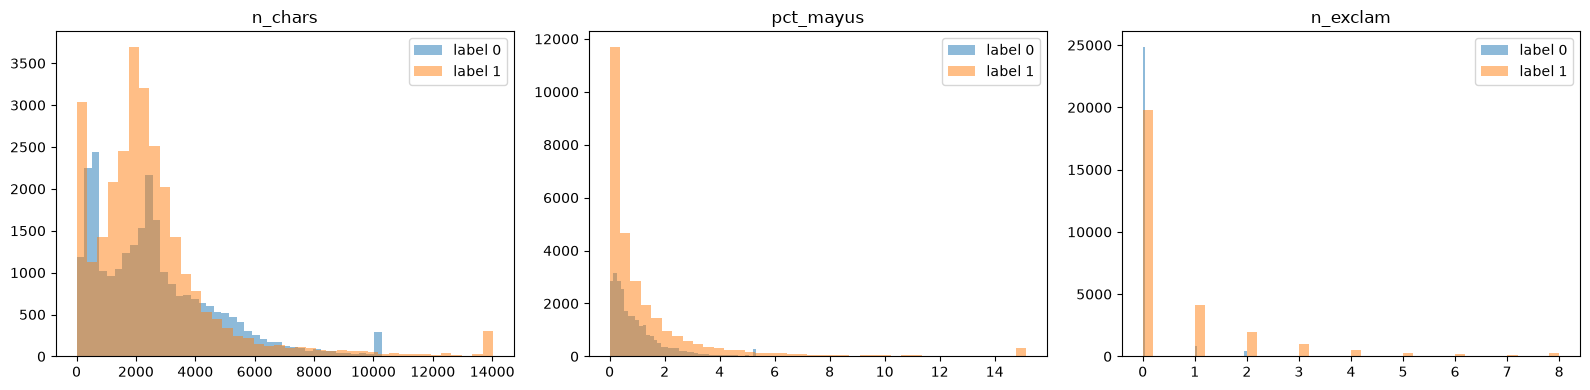

In [3]:

def main():
    df = Carga_Corpus(ruta_datos).cargar()
    display(Markdown(f"**{len(df):,} textos** · idiomas: {df['idioma'].value_counts().to_dict()} "
                     f"· labels: {df['label'].value_counts().to_dict()}"))
    inventario = seccion_caracteres(df)
    perfil = seccion_perfil(df, inventario)
    seccion_emojis(df)
    seccion_palabras_raras(df)
    resultados = seccion_detonantes(df)
    seccion_contexto(df, resultados)
    seccion_ortografia(df)
    graficar(perfil)

main()